# 01 - Exploratory data analysis
**Question:** do Punjab-Haryana farm fires help predict Delhi's next-day PM2.5?

This notebook regenerates every EDA figure with `src/plots.py` and explains each one.
All cleaning logic lives in `src/clean_*.py`; the decisions are summarised first.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
import config as C
pd.set_option("display.precision", 2)

In [2]:
import plots
plots.eda_figures()   # writes reports/figures/00-09

## Data after cleaning

In [3]:
aqi = pd.read_parquet(C.AQI_CLEAN); fires = pd.read_parquet(C.FIRES_DAILY)
weather = pd.read_parquet(C.WEATHER_CLEAN); table = pd.read_parquet(C.MODEL_TABLE)
for f in ["aqi", "fires", "weather"]:
    print(f, json.loads((C.INTERIM / f"{f}_cleaning_log.json").read_text()))
print("model table:", table.shape)
aqi.pm25.describe()

aqi {'rows': 2009, 'start': '2015-01-01', 'end': '2020-07-01', 'duplicate_dates_dropped': 0, 'calendar_days_added': 0, 'negative_set_nan': 0, 'above_1000_set_nan': 0, 'columns_dropped_gt40pct_missing': [], 'pm25_missing_frac': 0.001}
fires {'raw_rows': 482420, 'after_type_conf_filter': 439543, 'in_bbox': 119987, 'exact_duplicates_dropped': 0, 'ist_date_differs_from_utc': 343, 'days': 2009, 'days_with_zero_fires': 582}
weather {'days': 2009, 'start': '2015-01-01', 'end': '2020-07-01', 'missing_values': 0}
model table: (2006, 36)


count    2007.00
mean      117.20
std        82.91
min        10.24
25%        57.09
50%        94.62
75%       153.03
max       685.36
Name: pm25, dtype: float64

**Cleaning decisions (issue -> action -> reason)**

| Issue | Action | Reason |
|---|---|---|
| Duplicate dates | Checked and asserted: 0 found | One row per day is required for lags |
| Missing days | Reindexed to a full calendar, so gaps are explicit NaN | Lags must mean "yesterday", not "the previous row" |
| PM2.5 missing (0.1%, 2 days) | Target never imputed: those rows are dropped | Imputing the target would invent ground truth |
| Feature gaps | Forward-fill, at most 3 days | Uses the past only; interpolation would look into the future |
| Negative values or PM > 1000 | Rule in place: set to NaN as sensor errors (0 found) | Physically impossible |
| Extreme but real values (up to 685) | **Kept** | These smog episodes are exactly what we want to predict |
| Fire detections | `type == 0`, confidence >= 30, inside the Punjab+Haryana box | Vegetation fires only; drops low-confidence pixels |
| Fire time zone | UTC -> IST before daily aggregation (343 detections move date) | Daily features must align with Delhi's calendar days |
| Days without fires | 0, not NaN (582 days) | No detection is real information |
| Weather | Asserted no gaps in ERA5 | Reanalysis is complete by construction |

## 0. Missing values over time

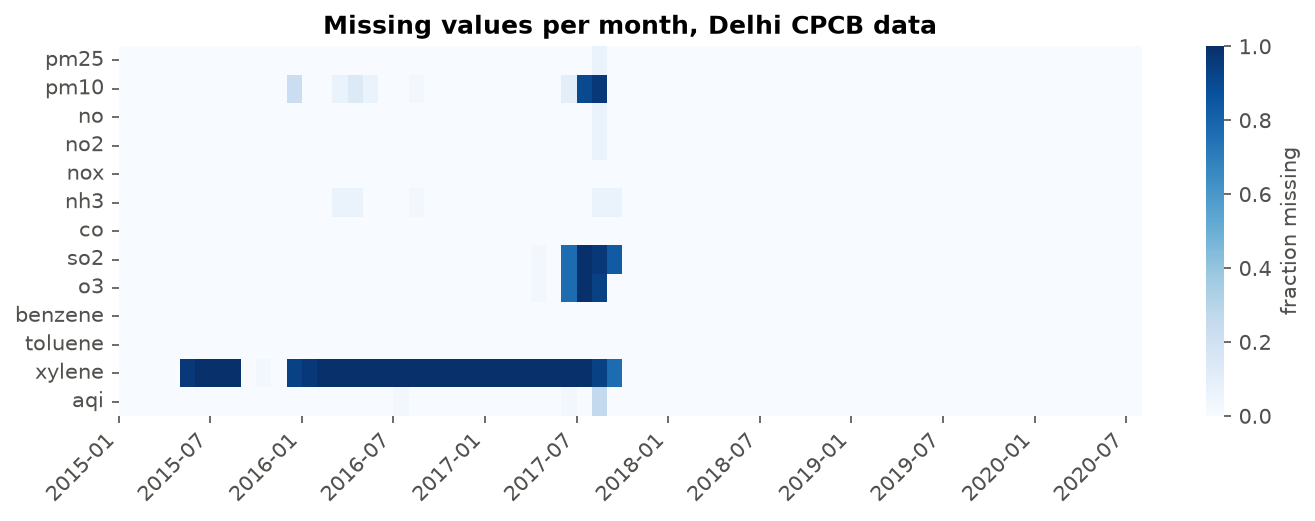

In [4]:
display(Image(C.FIGURES / "00_missingness.png"))

**What this shows.** Delhi's CPCB record is almost complete: PM2.5 and NO2 are missing on about 0.1% of days (2 days) and CO on none. Only Xylene (39%) and, to a lesser degree, SO2/O3/PM10 (4-5%) have gaps, and they cluster in blocks (mid-2015 to late 2017, mostly a 2017 monitoring outage) rather than being scattered. Xylene sits just under the 40% drop rule but is not used as a feature. Missingness is therefore not a threat to this analysis.

## 1. PM2.5 over time

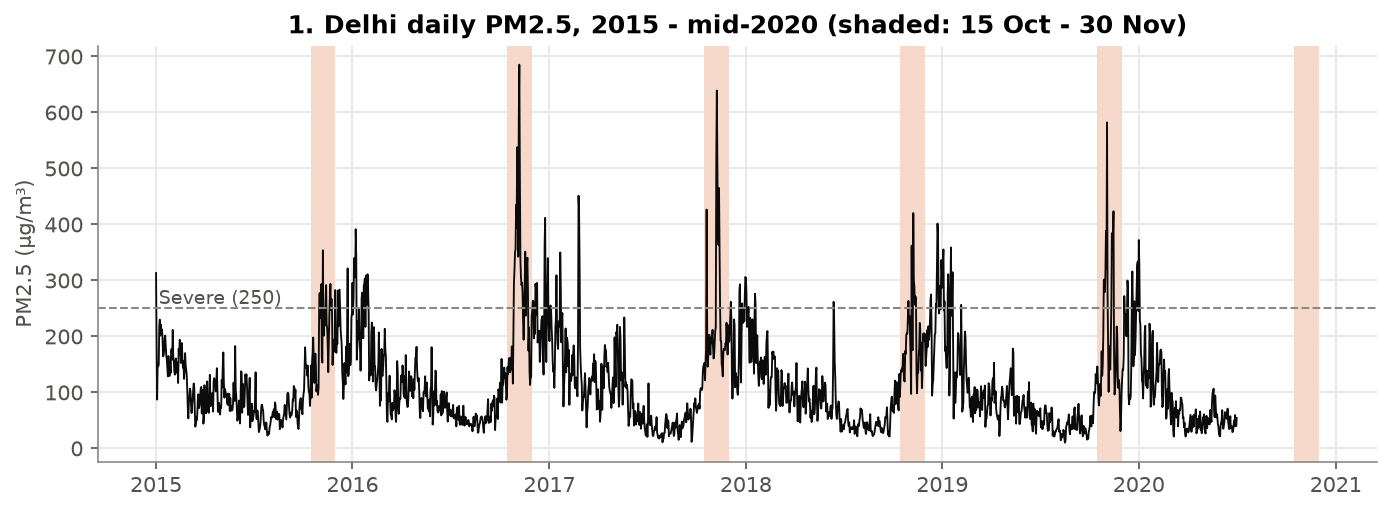

In [5]:
display(Image(C.FIGURES / "01_pm25_timeseries.png"))

**What this shows.** There is a sharp spike every year that starts in the shaded 15 Oct - 30 Nov window, with peaks of up to 685 ug/m3, more than 10x the national 24-h standard of 60. The median PM2.5 in the burning window is 190 vs 83 on other days. High values continue into December and January, *after* most fires stop, which already suggests winter weather is a major driver on its own.

## 2. Seasonality

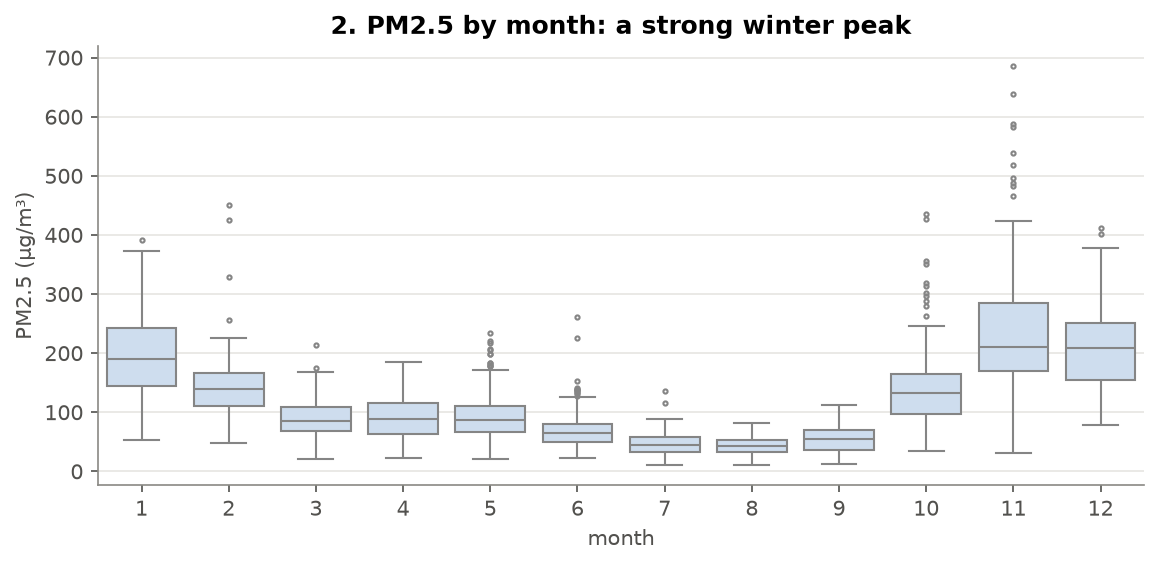

In [6]:
display(Image(C.FIGURES / "02_monthly_box.png"))

**What this shows.** Monthly medians run from about 43 (Aug, monsoon washout) to 210 (Nov-Dec). Seasonality alone explains much of the variance, so the seasonal-mean baseline (B1) is needed to show what a model adds beyond 'it is November'. The wide boxes in Oct-Jan show that day-to-day variation is largest exactly when it matters.

## 3. Fires and PM2.5 together

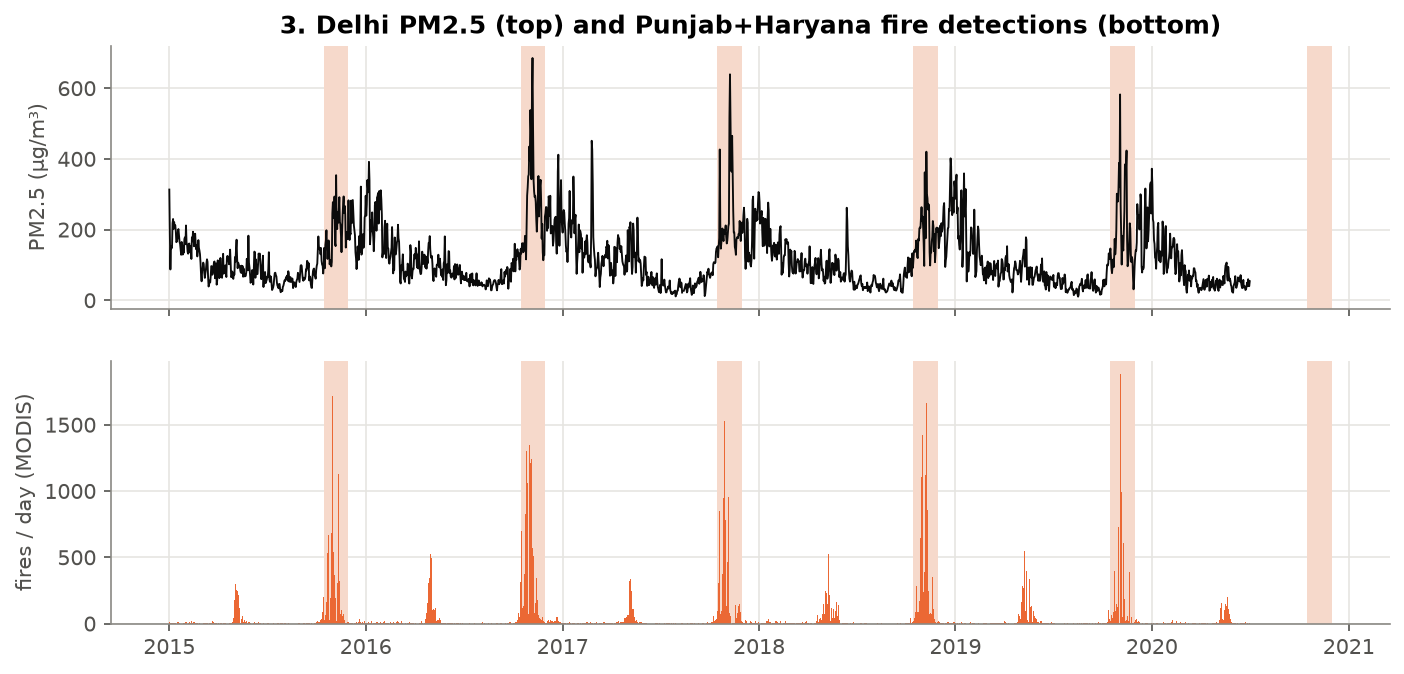

In [7]:
display(Image(C.FIGURES / "03_fires_vs_pm25.png"))

**What this shows.** Fire detections come in two seasons: the large kharif (rice) stubble season in Oct-Nov and a smaller rabi (wheat) one in April-May. 69% of all detections fall in the 15 Oct - 30 Nov window. The Oct-Nov fire peaks line up with the start of the PM2.5 peaks, but the April-May fires produce **no** matching PM2.5 spike. Summer weather (strong winds, deep mixing layer) disperses the smoke, a first hint that fires matter only when the weather lets them.

## 4. Where the fires are

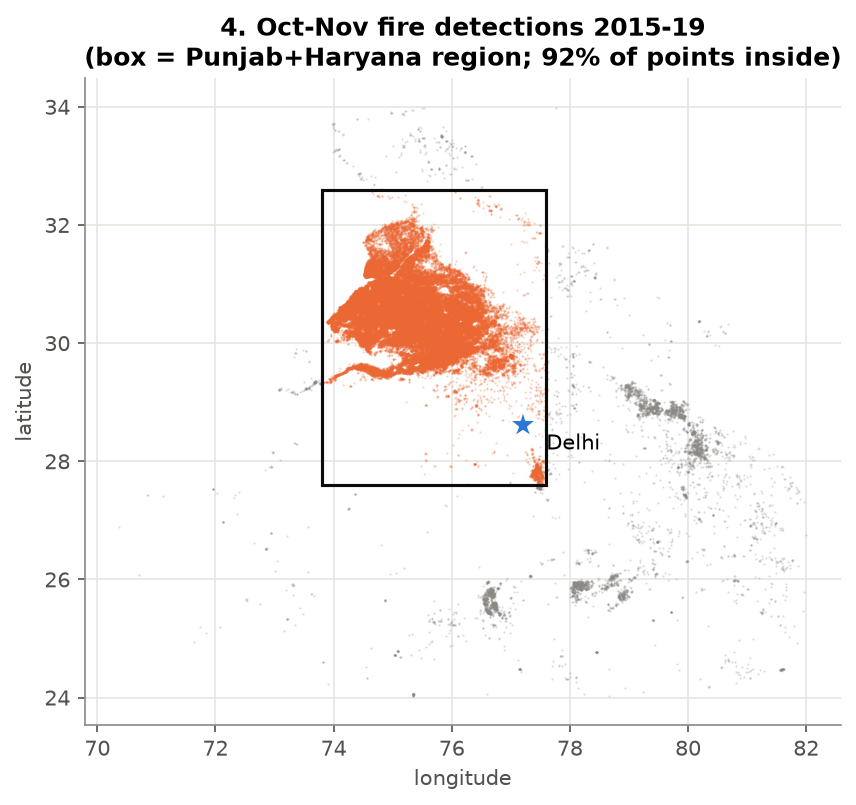

In [8]:
display(Image(C.FIGURES / "04_fire_map.png"))

**What this shows.** The bounding box captures the dense Punjab-Haryana burning belt: 92% of Oct-Nov detections in the wider window fall inside it. It also includes a small cluster at its south-east corner (around 27.7N, 77.5E, western Uttar Pradesh), and the box is not a state polygon. This is a stated limitation.

## 5. Which fire lags matter?

In [9]:
pd.read_csv(C.METRICS / "eda_lag_correlation.csv", index_col=0)

,all days,Oct-Nov only
lag,,
0,0.40,0.27
1,0.41,0.30
2,0.42,0.38
3,0.43,0.45
4,0.43,0.48
5,0.42,0.48


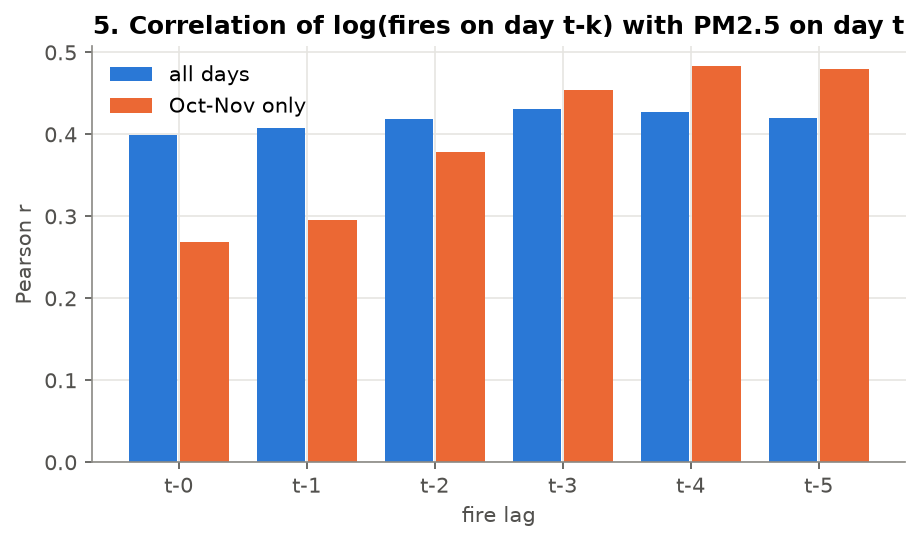

In [10]:
display(Image(C.FIGURES / "05_lag_correlation.png"))

**What this shows.** Over all days the correlation (~0.40-0.43) is inflated by the shared season. Inside Oct-Nov only, the correlation **rises with lag**, from 0.27 at lag 0 to 0.48 at lags 4-5. Smoke takes days to accumulate over Delhi, so the 3- and 7-day rolling fire sums are justified features. A correlation is not a causal effect: both series also follow the seasonal decline in temperature and mixing height.

## 6. Weather confounders

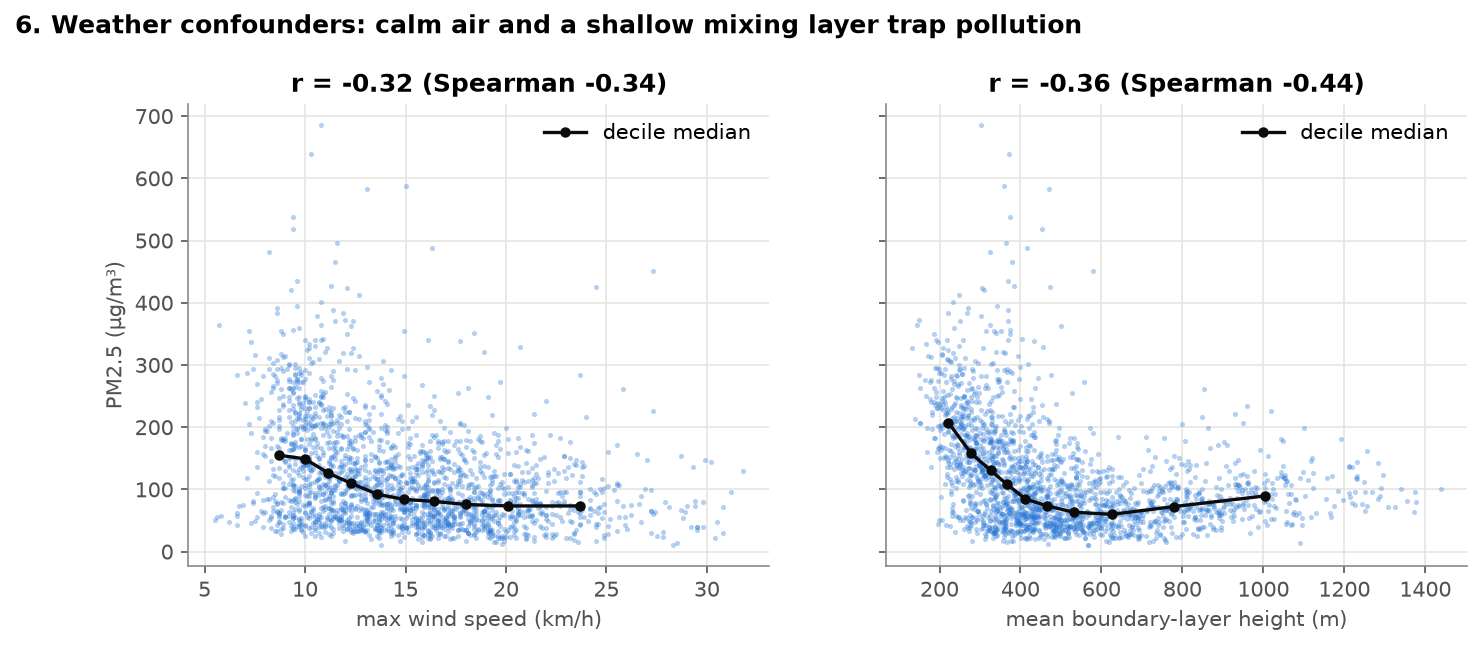

In [11]:
display(Image(C.FIGURES / "06_weather_vs_pm25.png"))

**What this shows.** PM2.5 falls with wind speed (Spearman -0.34) and with boundary-layer height (-0.44). Temperature (-0.53) and rain (-0.54) are even stronger. Calm, cold, shallow-mixing days trap pollution. These conditions coincide with the burning season, so a model **without** weather would wrongly credit fires with the winter effect. That is why the no-fires comparison model includes all weather features.

## 7. Is the wind from Punjab on bad days?

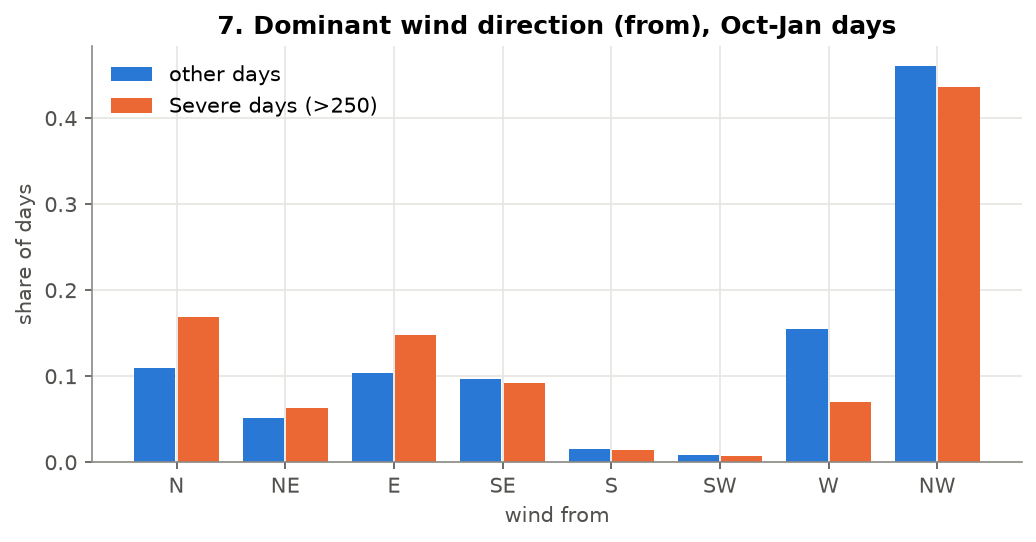

In [12]:
display(Image(C.FIGURES / "07_wind_direction.png"))

**What this shows.** In Oct-Jan, north-westerly winds (from Punjab/Haryana) are the most common direction on *all* days (about 45%), and Severe days are **not** more often NW than other days. W winds are actually rarer on Severe days, and calm N/E days are more common. Wind direction alone does not separate bad days. Transport probably matters only together with fire activity and low wind speed, hence the `fire_roll3 x nw_wind` interaction feature.

## 8. Feature correlations

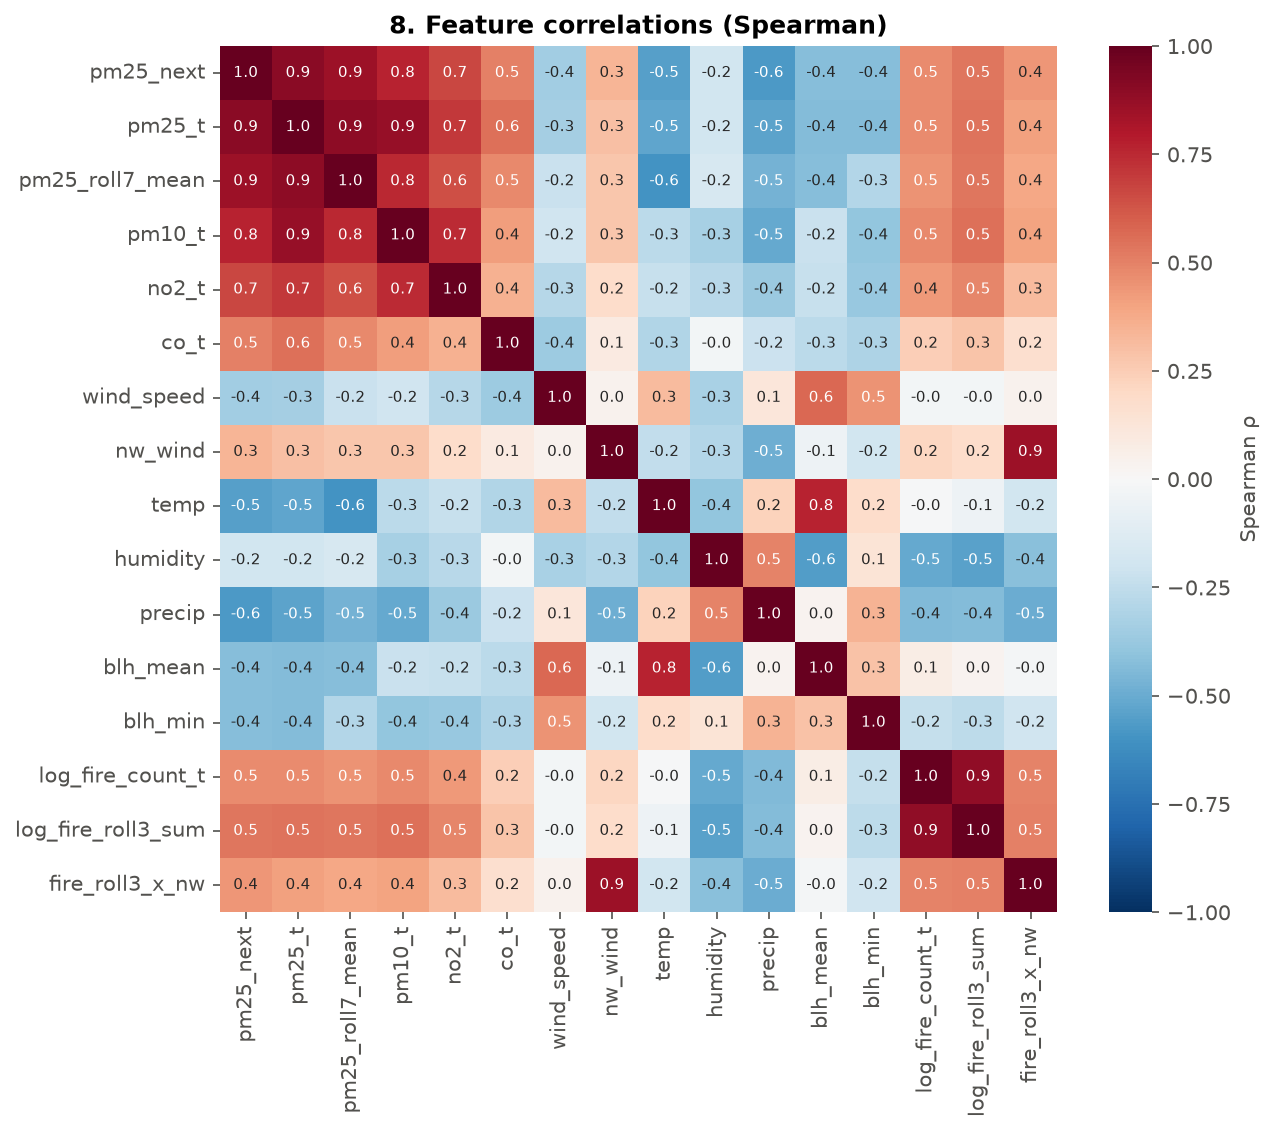

In [13]:
display(Image(C.FIGURES / "08_corr_heatmap.png"))

**What this shows.** Tomorrow's PM2.5 correlates most strongly with today's PM2.5 (rho 0.90) and its 3/7-day means (0.88/0.86). Persistence will dominate every model. Fire features correlate with the target at 0.44-0.54, but also with temperature and humidity, so their *added* value after the persistence and weather features is the real question, not their raw correlation. The PM lags are strongly collinear, which is why Ridge (L2) is used rather than plain OLS.

## 9. Diwali, a confounder inside the burning season

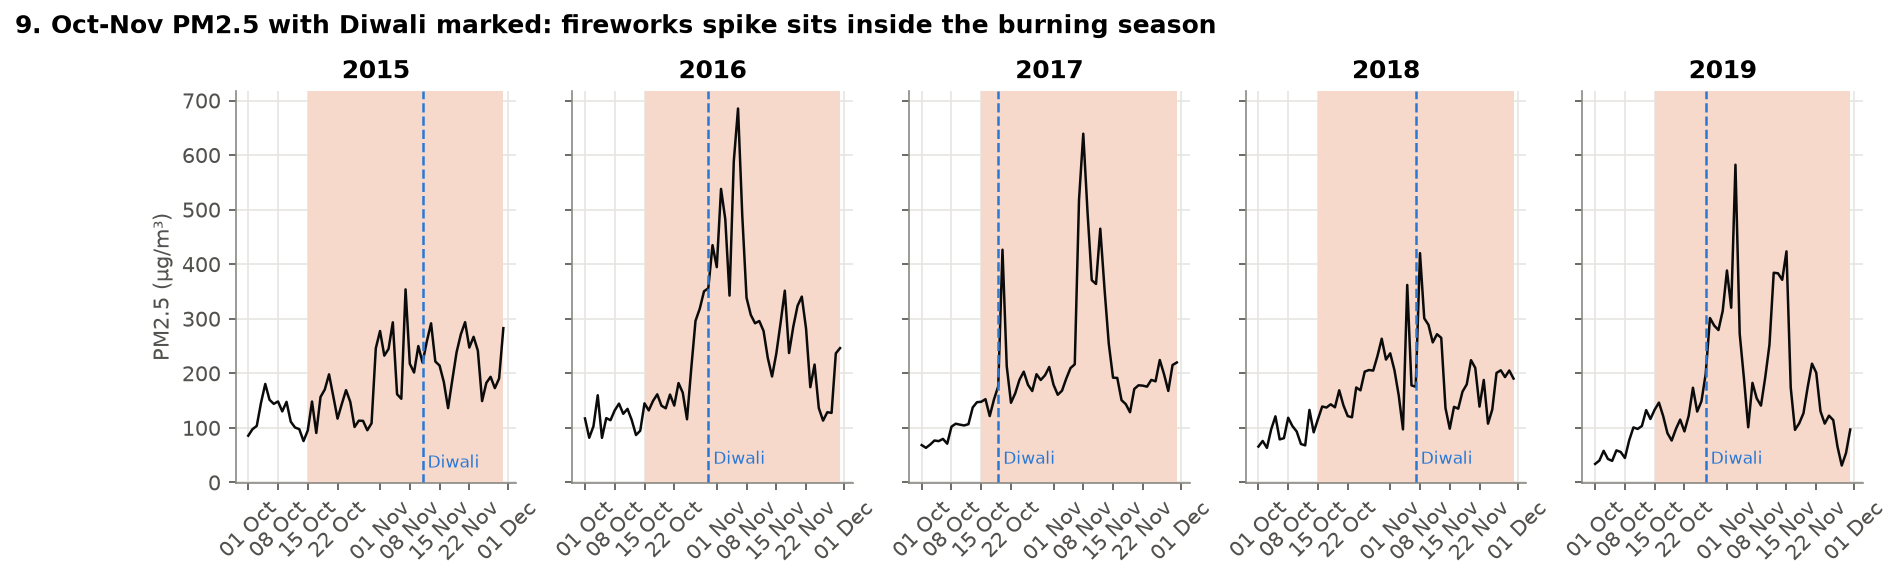

In [14]:
display(Image(C.FIGURES / "09_diwali.png"))

**What this shows.** Diwali falls inside or next to the burning window every year, and PM2.5 typically jumps on the day after (e.g. 2017: 176 -> 427; 2018: 175 -> 420). Without a Diwali flag a model could attribute the fireworks spike to fires, so `is_diwali_window` (+/-2 days) is included in **both** model variants.

## EDA conclusions that shape the modelling
1. Strong persistence, so **persistence is the baseline to beat**, and PM lags/rolling means are features.
2. Strong seasonality and weather confounding, so the no-fires model must include weather and calendar features to make the fire test fair.
3. Fire -> PM2.5 correlation peaks at 3-5 day lags, so rolling 3- and 7-day fire sums are used.
4. Spring fires show no PM signal, so a fire x wind interaction is used, and the gain is evaluated specifically in the burning season.